<a href="https://colab.research.google.com/github/ohabuenyirita/pipeline-sensor-anomaly-detection/blob/main/Real_Time_Pipeline_Sensor_Anomaly_Engine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest

In [ ]:
# Set seed for reproducibility
np.random.seed(42)

1. GENERATE / PREPARE SENSOR TIME-SERIES DATA

In [ ]:
print("1. Loading Pipeline Sensor Data...")

1. Loading Pipeline Sensor Data...


In [ ]:
# Create 1,000 hourly timestamps (approx. 40 days of pipeline monitoring)
dates = pd.date_range(start="2026-01-01", periods=1000, freq="h")

In [ ]:
# Simulate baseline operational metrics
tubing_pressure = 150 + np.sin(np.linspace(0, 50, 1000)) * 10 + np.random.normal(0, 2, 1000) # PSI
flow_rate = 2500 + np.sin(np.linspace(0, 50, 1000)) * 100 + np.random.normal(0, 15, 1000)   # Barrels/day
temperature = 65 + np.random.normal(0, 1, 1000)

In [ ]:
df = pd.DataFrame({
    'timestamp': dates,
    'tubing_pressure_psi': tubing_pressure,
    'flow_rate_bpd': flow_rate,
    'temperature_c': temperature
})

In [ ]:
# Inject real-world pipeline anomalies (e.g., sudden pressure drop = leak, pressure spike = blockage)
anomaly_indices = [150, 151, 152, 420, 421, 780, 781, 782, 783]
df.loc[anomaly_indices[0:3], 'tubing_pressure_psi'] -= 45   # Pressure drop (leakage event)
df.loc[anomaly_indices[3:5], 'tubing_pressure_psi'] += 55   # Sudden blockage spike
df.loc[anomaly_indices[5:], 'flow_rate_bpd'] -= 1200        # Sudden flow reduction

In [ ]:
# Set timestamp as index
df.set_index('timestamp', inplace=True)

2. TIME-SERIES FEATURE ENGINEERING

In [ ]:
print("2. Engineering Rolling Statistical Features...")

2. Engineering Rolling Statistical Features...


In [ ]:
# Calculate rolling statistics (moving average, variance, rate of change)
df['pressure_rolling_mean'] = df['tubing_pressure_psi'].rolling(window=12).mean()
df['pressure_rolling_std'] = df['tubing_pressure_psi'].rolling(window=12).std()
df['pressure_rate_of_change'] = df['tubing_pressure_psi'].diff()

df['flow_rolling_mean'] = df['flow_rate_bpd'].rolling(window=12).mean()
df['flow_rolling_std'] = df['flow_rate_bpd'].rolling(window=12).std()

In [ ]:
# Drop initial NaNs from rolling window calculation
feature_df = df.dropna()

3. TRAIN ISOLATION FOREST ANOMALY DETECTOR

In [ ]:
print("3. Training Isolation Forest Model...")

3. Training Isolation Forest Model...


In [ ]:
feature_cols = [
    'tubing_pressure_psi', 'flow_rate_bpd', 'temperature_c',
    'pressure_rolling_mean', 'pressure_rolling_std', 'pressure_rate_of_change',
    'flow_rolling_mean', 'flow_rolling_std'
]

In [ ]:
# Contamination = ~2% expected operational anomalies
model = IsolationForest(n_estimators=100, contamination=0.02, random_state=42)
model.fit(feature_df[feature_cols])

IsolationForest(contamination=0.02, random_state=42)

In [ ]:
# Predictions: -1 indicates anomaly, 1 indicates normal
feature_df['anomaly_score'] = model.decision_function(feature_df[feature_cols])
feature_df['is_anomaly'] = model.predict(feature_df[feature_cols])

/tmp/ipykernel_2323/662526789.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  feature_df['anomaly_score'] = model.decision_function(feature_df[feature_cols])
/tmp/ipykernel_2323/662526789.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  feature_df['is_anomaly'] = model.predict(feature_df[feature_cols])


In [ ]:
# Predictions: -1 indicates anomaly, 1 indicates normal
feature_df['anomaly_score'] = model.decision_function(feature_df[feature_cols])
feature_df['is_anomaly'] = model.predict(feature_df[feature_cols])

detected_anomalies = feature_df[feature_df['is_anomaly'] == -1]
print(f"-> Successfully detected {len(detected_anomalies)} anomaly events out of {len(feature_df)} sensor readings.")

-> Successfully detected 20 anomaly events out of 989 sensor readings.


/tmp/ipykernel_2323/2045590918.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  feature_df['anomaly_score'] = model.decision_function(feature_df[feature_cols])
/tmp/ipykernel_2323/2045590918.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  feature_df['is_anomaly'] = model.predict(feature_df[feature_cols])


### 4. PLOT HIGH-IMPACT VISUAL FOR SOCIAL MEDIA

4. Generating Visualization...


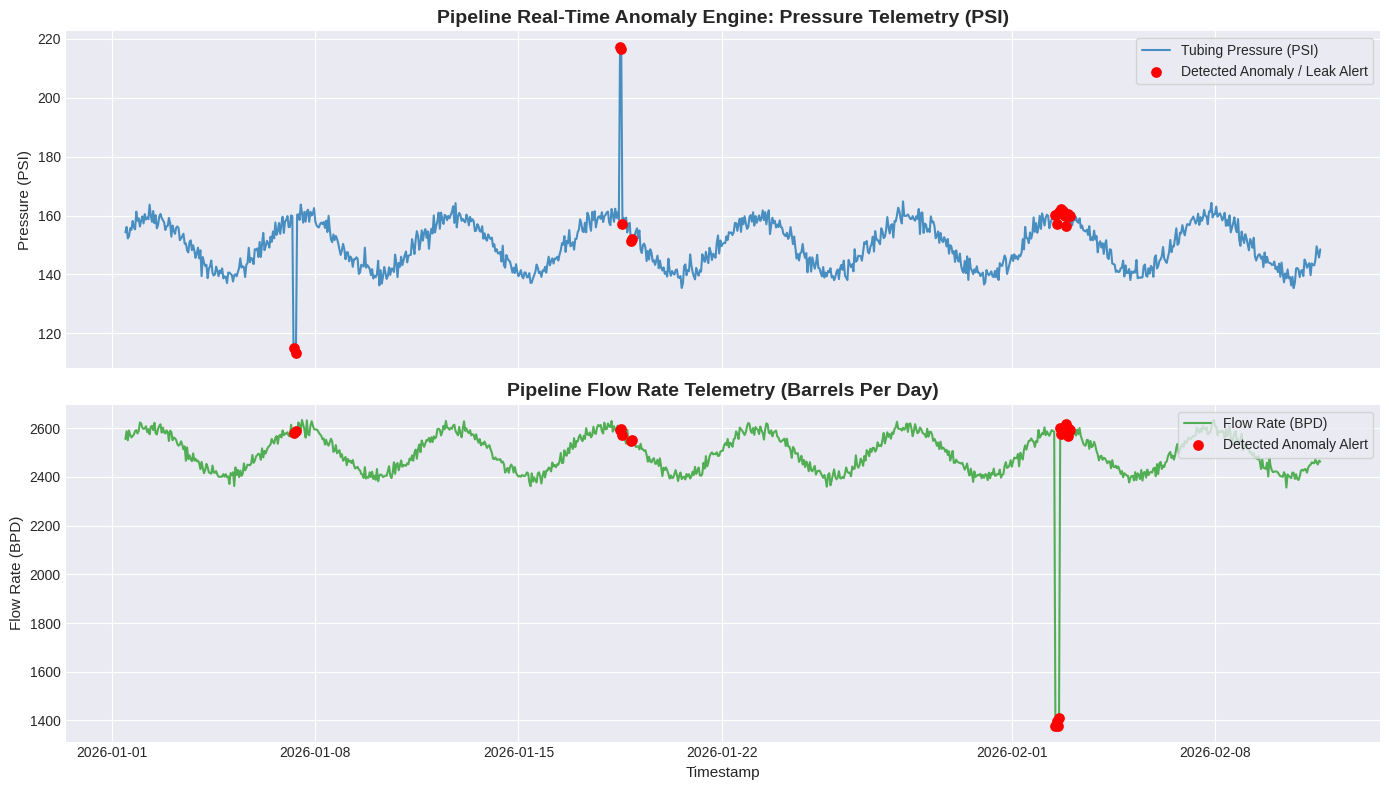

In [ ]:
print("4. Generating Visualization...")

plt.style.use('seaborn-v0_8-darkgrid' if 'seaborn-v0_8-darkgrid' in plt.style.available else 'default')
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Top Chart: Pressure & Detected Anomalies
ax1.plot(feature_df.index, feature_df['tubing_pressure_psi'], label='Tubing Pressure (PSI)', color='#1f77b4', alpha=0.8)
ax1.scatter(detected_anomalies.index, detected_anomalies['tubing_pressure_psi'],
            color='red', label='Detected Anomaly / Leak Alert', s=45, zorder=5)
ax1.set_title('Pipeline Real-Time Anomaly Engine: Pressure Telemetry (PSI)', fontsize=14, fontweight='bold')
ax1.set_ylabel('Pressure (PSI)', fontsize=11)
ax1.legend(loc='upper right', frameon=True)

# Bottom Chart: Flow Rate & Detected Anomalies
ax2.plot(feature_df.index, feature_df['flow_rate_bpd'], label='Flow Rate (BPD)', color='#2ca02c', alpha=0.8)
ax2.scatter(detected_anomalies.index, detected_anomalies['flow_rate_bpd'],
            color='red', label='Detected Anomaly Alert', s=45, zorder=5)
ax2.set_title('Pipeline Flow Rate Telemetry (Barrels Per Day)', fontsize=14, fontweight='bold')
ax2.set_ylabel('Flow Rate (BPD)', fontsize=11)
ax2.set_xlabel('Timestamp', fontsize=11)
ax2.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.savefig('pipeline_anomaly_detection.png', dpi=300)
plt.show()

In [ ]:
from google.colab import files

# This will trigger an automatic browser download of your chart
files.download('pipeline_anomaly_detection.png')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>